# Explainable AI (XAI) for CNN Image Classification — Google Colab

**Practical objective:** Train a CNN on the Kaggle COVID-19 Radiography Database, visualize feature maps from an early and a deeper convolutional layer, and use Grad-CAM to highlight image regions that influence a selected class prediction.

This notebook is designed for Google Colab. It downloads the Kaggle dataset into Google Drive, creates stratified train/validation/test splits, trains a four-class CNN, evaluates it, and generates XAI visualizations.

**Classes:** COVID, Lung_Opacity, Normal, Viral Pneumonia.

> **Important:** This is an educational image-classification exercise, not a medical diagnostic system. Grad-CAM visualizations show model sensitivity/attention patterns; they do not establish clinical evidence or causality.

## Before running
1. In Colab, select **Runtime → Change runtime type → T4 GPU** (or another available GPU).
2. Create a Kaggle API token from [Kaggle Account → Settings → API](https://www.kaggle.com/settings/api).
3. Recommended: add a Colab Secret named `KAGGLE_API_TOKEN`, paste the token as its value, and enable notebook access to it. Alternatively, the authentication cell will display a secure KaggleHub login widget.
4. Run the cells from top to bottom. The first dataset download can take time and requires sufficient Google Drive storage.

The dataset layout used by the notebook is the published layout with class folders containing `images/` and `masks/` subfolders. The notebook uses **images only** and does not train on the masks.

## 1. Install libraries and import packages

In [4]:
%pip -q install -U kagglehub scikit-learn seaborn

import os
import re
import random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Mount Google Drive and authenticate with Kaggle

In [5]:
from google.colab import drive

drive.mount('/content/drive')

import os
import kagglehub

# Permanent dataset storage location
drive_path = "/content/drive/MyDrive/Datasets/COVID19_Radiography"

os.makedirs(drive_path, exist_ok=True)

# Download directly into Google Drive
path = kagglehub.dataset_download(
    "tawsifurrahman/covid19-radiography-database",
    output_dir=drive_path
)

print("Dataset downloaded successfully!")
print("Dataset path:", path)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Using Colab cache for faster access to the 'covid19-radiography-database' dataset.
Dataset downloaded successfully!
Dataset path: /kaggle/input/covid19-radiography-database


## 3. Download the dataset directly into Google Drive

`output_dir` downloads the dataset to the chosen Drive directory instead of relying on a temporary Colab cache. If the download already exists, KaggleHub can reuse the files in that output directory.

In [6]:
DATASET_ID = "tawsifurrahman/covid19-radiography-database"
DRIVE_DATA_DIR = "/content/drive/MyDrive/Datasets/COVID19_Radiography"
os.makedirs(DRIVE_DATA_DIR, exist_ok=True)

# Download dataset directly to Google Drive.
dataset_path = kagglehub.dataset_download(
    DATASET_ID,
    output_dir=DRIVE_DATA_DIR
)

print("Dataset returned path:", dataset_path)
print("Google Drive destination:", DRIVE_DATA_DIR)

Using Colab cache for faster access to the 'covid19-radiography-database' dataset.
Dataset returned path: /kaggle/input/covid19-radiography-database
Google Drive destination: /content/drive/MyDrive/Datasets/COVID19_Radiography


## 4. Locate image folders and inspect class counts

The code handles the common Kaggle layout where each class folder contains an `images/` folder and a `masks/` folder. Only files inside `images/` are selected. If a class has images directly inside its class folder, those direct image files are used instead.

In [7]:
# Canonical class order used throughout the notebook.
CLASS_NAMES = ["COVID", "Lung_Opacity", "Normal", "Viral Pneumonia"]
IMAGE_SUFFIXES = {".png", ".jpg", ".jpeg", ".bmp"}


def normalize_folder_name(name):
    """Normalize folder names so spaces, underscores and hyphens do not matter."""
    return re.sub(r"[^a-z0-9]", "", name.lower())


CLASS_NAME_LOOKUP = {
    "covid": "COVID",
    "lungopacity": "Lung_Opacity",
    "normal": "Normal",
    "viralpneumonia": "Viral Pneumonia",
}


def find_class_directories(search_root):
    """Find the four class directories anywhere below search_root."""
    found = {}
    search_root = Path(search_root)

    for directory in search_root.rglob("*"):
        if not directory.is_dir():
            continue
        normalized = normalize_folder_name(directory.name)
        if normalized in CLASS_NAME_LOOKUP:
            canonical = CLASS_NAME_LOOKUP[normalized]
            # Prefer the first matching folder that contains usable image files.
            image_dir = directory / "images"
            candidate_dir = image_dir if image_dir.is_dir() else directory
            has_images = any(
                p.is_file() and p.suffix.lower() in IMAGE_SUFFIXES
                for p in candidate_dir.iterdir()
            )
            if has_images and canonical not in found:
                found[canonical] = directory

    missing = [name for name in CLASS_NAMES if name not in found]
    if missing:
        raise FileNotFoundError(
            f"Could not find image folders for: {missing}. "
            f"Inspect the downloaded directory: {search_root}"
        )
    return found


class_dirs = find_class_directories(dataset_path)

image_paths = []
image_labels = []
class_counts = {}

for class_index, class_name in enumerate(CLASS_NAMES):
    class_dir = class_dirs[class_name]
    images_dir = class_dir / "images"
    source_dir = images_dir if images_dir.is_dir() else class_dir

    files_for_class = sorted([
        p for p in source_dir.iterdir()
        if p.is_file() and p.suffix.lower() in IMAGE_SUFFIXES
    ])

    if not files_for_class:
        raise RuntimeError(f"No image files found for class {class_name} in {source_dir}")

    image_paths.extend([str(p) for p in files_for_class])
    image_labels.extend([class_index] * len(files_for_class))
    class_counts[class_name] = len(files_for_class)

image_paths = np.asarray(image_paths)
image_labels = np.asarray(image_labels, dtype=np.int32)

print("Class folders:")
for name in CLASS_NAMES:
    print(f"  {name}: {class_dirs[name]}")
print("\nImage counts:")
for name, count in class_counts.items():
    print(f"  {name}: {count:,}")
print(f"\nTotal images: {len(image_paths):,}")

if len(image_paths) == 0:
    raise RuntimeError("No images were found. Check the dataset download and folder layout.")

Class folders:
  COVID: /kaggle/input/covid19-radiography-database/COVID-19_Radiography_Dataset/COVID
  Lung_Opacity: /kaggle/input/covid19-radiography-database/COVID-19_Radiography_Dataset/Lung_Opacity
  Normal: /kaggle/input/covid19-radiography-database/COVID-19_Radiography_Dataset/Normal
  Viral Pneumonia: /kaggle/input/covid19-radiography-database/COVID-19_Radiography_Dataset/Viral Pneumonia

Image counts:
  COVID: 3,616
  Lung_Opacity: 6,012
  Normal: 10,192
  Viral Pneumonia: 1,345

Total images: 21,165


## 5. Create stratified training, validation and test splits

The split is 70% training, 15% validation and 15% test. Stratification keeps approximately the same class proportions in each split. Class weights are also calculated because this dataset has unequal class counts.

In [8]:
X_train, X_temp, y_train, y_temp = train_test_split(
    image_paths,
    image_labels,
    test_size=0.30,
    random_state=SEED,
    stratify=image_labels
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print(f"Training images:   {len(X_train):,}")
print(f"Validation images: {len(X_val):,}")
print(f"Test images:       {len(X_test):,}")

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)
class_weight_dict = {
    int(class_id): float(weight)
    for class_id, weight in zip(np.unique(y_train), class_weights_array)
}
print("\nClass weights:")
for class_id, weight in class_weight_dict.items():
    print(f"  {CLASS_NAMES[class_id]}: {weight:.3f}")

Training images:   14,815
Validation images: 3,175
Test images:       3,175

Class weights:
  COVID: 1.463
  Lung_Opacity: 0.880
  Normal: 0.519
  Viral Pneumonia: 3.932


## 6. Build TensorFlow input pipelines

Images are decoded as three-channel images and resized to 224 × 224. Pixel scaling is performed inside the model, so the images passed to the model remain in the 0–255 range for visualization.

In [9]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE


def load_image(file_path, label):
    image_bytes = tf.io.read_file(file_path)
    image = tf.io.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)
    return image, label


def make_dataset(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if training:
        ds = ds.shuffle(
            buffer_size=min(len(paths), 5000),
            seed=SEED,
            reshuffle_each_iteration=True
        )
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)
    return ds

train_ds = make_dataset(X_train, y_train, training=True)
val_ds = make_dataset(X_val, y_val, training=False)
test_ds = make_dataset(X_test, y_test, training=False)

print("TensorFlow datasets are ready.")

TensorFlow datasets are ready.


## 7. Display sample images

This is a visual check that image loading and class labels are correct.

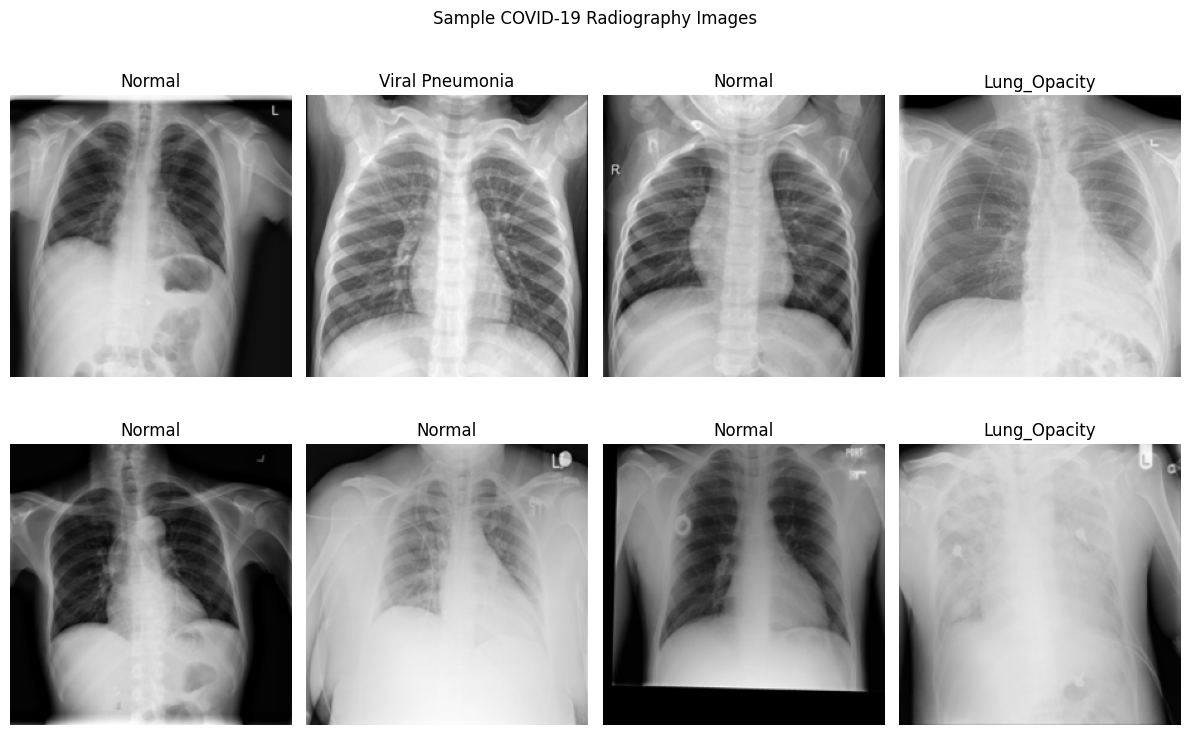

In [10]:
plt.figure(figsize=(12, 8))
for images, labels in train_ds.take(1):
    n_show = min(8, int(images.shape[0]))
    for i in range(n_show):
        plt.subplot(2, 4, i + 1)
        plt.imshow(tf.cast(images[i], tf.uint8).numpy())
        plt.title(CLASS_NAMES[int(labels[i].numpy())])
        plt.axis("off")
plt.suptitle("Sample COVID-19 Radiography Images")
plt.tight_layout()
plt.show()

## 8. Build the CNN image classifier

This practical uses a compact CNN with three convolutional layers. The first and third convolutional layers will be used later for feature-map visualization and Grad-CAM.

In [11]:
NUM_CLASSES = len(CLASS_NAMES)

# Mild augmentation. Horizontal flipping is avoided for chest X-rays because
# left-right orientation can carry clinical meaning.
augmentation = keras.Sequential(
    [
        layers.RandomRotation(0.03),
        layers.RandomZoom(0.08),
        layers.RandomTranslation(height_factor=0.03, width_factor=0.03),
    ],
    name="data_augmentation"
)

inputs = keras.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3), name="input_image")
x = layers.Rescaling(1.0 / 255.0, name="rescaling")(inputs)
x = augmentation(x)

x = layers.Conv2D(32, (3, 3), padding="same", activation="relu", name="conv1")(x)
x = layers.MaxPooling2D((2, 2), name="pool1")(x)

x = layers.Conv2D(64, (3, 3), padding="same", activation="relu", name="conv2")(x)
x = layers.MaxPooling2D((2, 2), name="pool2")(x)

x = layers.Conv2D(128, (3, 3), padding="same", activation="relu", name="conv3")(x)
x = layers.MaxPooling2D((2, 2), name="pool3")(x)

x = layers.GlobalAveragePooling2D(name="global_average_pooling")(x)
x = layers.Dropout(0.35, name="dropout")(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax", name="predictions")(x)

model = keras.Model(inputs=inputs, outputs=outputs, name="covid_xray_cnn")
model.summary()

Model: "covid_xray_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling          │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ predictions (Dense)             │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 93,764 (366.27 KB)

 Trainable params: 93,764 (366.27 KB)

 Non-trainable params: 0 (0.00 B)

## 9. Compile and train the CNN

The model uses Adam and sparse categorical cross-entropy because each image is assigned one integer class label. Early stopping restores the weights from the epoch with the best validation loss.

In [12]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

OUTPUT_DIR = "/content/drive/MyDrive/XAI_CNN_Results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

checkpoint_path = os.path.join(OUTPUT_DIR, "best_cnn_model.keras")

callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    keras.callbacks.ModelCheckpoint(
        filepath=checkpoint_path,
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    )
]

EPOCHS = 12

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    class_weight=class_weight_dict,
    callbacks=callbacks
)

print("Best model saved to:", checkpoint_path)

Epoch 1/12
463/463 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step - accuracy: 0.2610 - loss: 1.3690
Epoch 1: val_loss improved from None to 1.13532, saving model to /content/drive/MyDrive/XAI_CNN_Results/best_cnn_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/XAI_CNN_Results/best_cnn_model.keras
463/463 ━━━━━━━━━━━━━━━━━━━━ 84s 167ms/step - accuracy: 0.3004 - loss: 1.3071 - val_accuracy: 0.4835 - val_loss: 1.1353
Epoch 2/12
463/463 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - accuracy: 0.4229 - loss: 1.0542
Epoch 2: val_loss improved from 1.13532 to 1.01998, saving model to /content/drive/MyDrive/XAI_CNN_Results/best_cnn_model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/XAI_CNN_Results/best_cnn_model.keras
463/463 ━━━━━━━━━━━━━━━━━━━━ 42s 90ms/step - accuracy: 0.4373 - loss: 1.0239 - val_accuracy: 0.5534 - val_loss: 1.0200
Epoch 3/12
463/463 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step - accuracy: 0.4788 - loss: 0.9727
Epoch 3: val_loss improved from 1.01998 to 0.97145, savi

## 10. Plot training and validation accuracy/loss

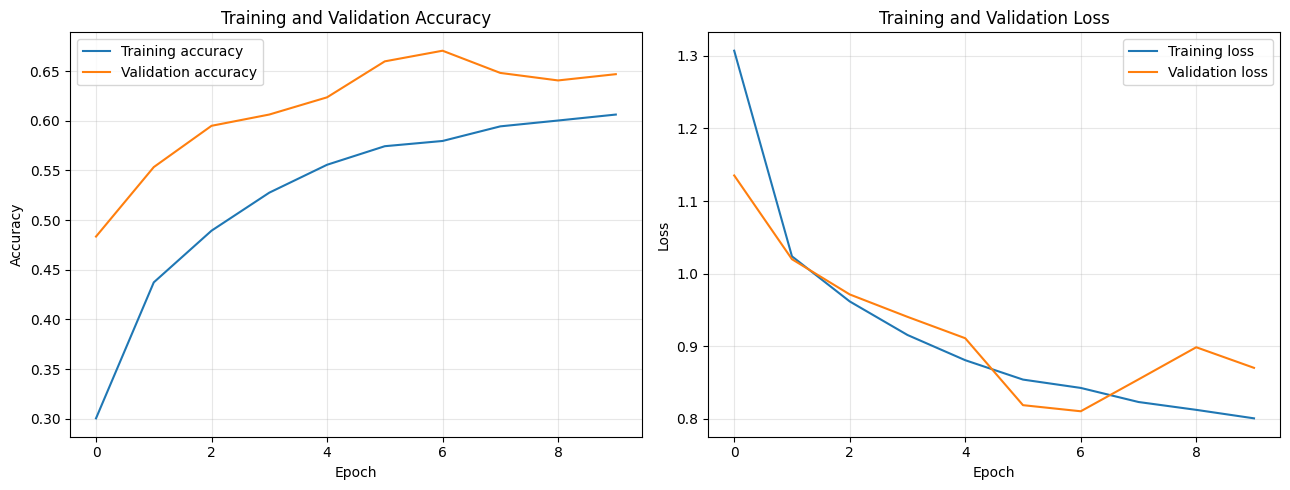

In [13]:
plt.figure(figsize=(13, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "training_curves.png"), dpi=150)
plt.show()

## 11. Evaluate the CNN on the held-out test set

100/100 ━━━━━━━━━━━━━━━━━━━━ 13s 134ms/step - accuracy: 0.6561 - loss: 0.8339
Test loss: 0.8339
Test accuracy: 65.61%
100/100 ━━━━━━━━━━━━━━━━━━━━ 7s 68ms/step

Classification report:
                 precision    recall  f1-score   support

          COVID       0.47      0.55      0.51       542
   Lung_Opacity       0.67      0.72      0.69       902
         Normal       0.78      0.63      0.70      1529
Viral Pneumonia       0.52      0.82      0.64       202

       accuracy                           0.66      3175
      macro avg       0.61      0.68      0.63      3175
   weighted avg       0.68      0.66      0.66      3175



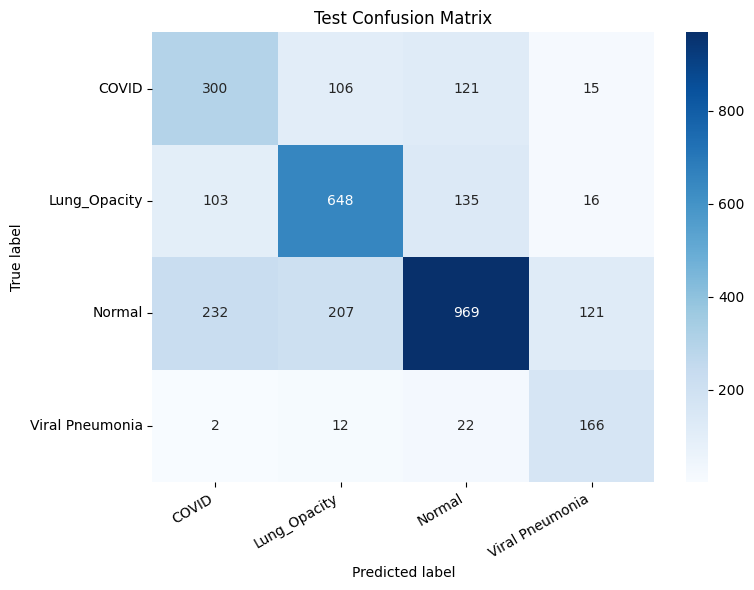

In [14]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy * 100:.2f}%")

# Predictions are in the same order as X_test because test_ds is not shuffled.
y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=CLASS_NAMES,
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred, labels=list(range(NUM_CLASSES)))
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Test Confusion Matrix")
plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "confusion_matrix.png"), dpi=150)
plt.show()

## 12. Select one test image for XAI visualization

The following cell selects a test image, displays it, and reports the model's prediction. The same image is used for feature-map and Grad-CAM visualizations.

Image: /kaggle/input/covid19-radiography-database/COVID-19_Radiography_Dataset/Normal/images/Normal-8250.png
Actual class: Normal
Predicted class: Normal
Prediction confidence: 49.97%


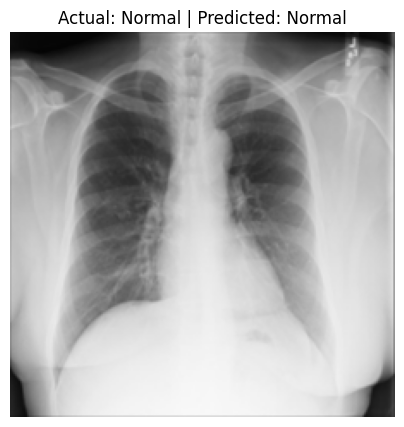

In [15]:
# Choose a test image by index. Change this value to inspect another image.
SAMPLE_INDEX = 0

sample_path = X_test[SAMPLE_INDEX]
actual_label = int(y_test[SAMPLE_INDEX])

# Load one image using the same preprocessing pipeline as training.
sample_image, _ = load_image(
    tf.constant(sample_path),
    tf.constant(actual_label, dtype=tf.int32)
)
sample_batch = tf.expand_dims(sample_image, axis=0)

sample_prediction = model.predict(sample_batch, verbose=0)[0]
predicted_class = int(np.argmax(sample_prediction))
confidence = float(sample_prediction[predicted_class])

print("Image:", sample_path)
print("Actual class:", CLASS_NAMES[actual_label])
print("Predicted class:", CLASS_NAMES[predicted_class])
print(f"Prediction confidence: {confidence * 100:.2f}%")

plt.figure(figsize=(5, 5))
plt.imshow(tf.cast(sample_image, tf.uint8).numpy())
plt.title(f"Actual: {CLASS_NAMES[actual_label]} | Predicted: {CLASS_NAMES[predicted_class]}")
plt.axis("off")
plt.show()

## 13. Generate feature maps from early and deeper convolutional layers

The early convolutional layer typically responds to simple local patterns, while deeper layers combine information into more task-specific patterns. These are learned activations, not human-readable labels for individual features.

In [16]:
feature_extractor = keras.Model(
    inputs=model.input,
    outputs=[
        model.get_layer("conv1").output,
        model.get_layer("conv3").output
    ],
    name="feature_extractor"
)

early_maps, deep_maps = feature_extractor(sample_batch, training=False)

early_maps = early_maps[0].numpy()
deep_maps = deep_maps[0].numpy()

print("Early-layer feature-map shape:", early_maps.shape)
print("Deep-layer feature-map shape:", deep_maps.shape)

Early-layer feature-map shape: (224, 224, 32)
Deep-layer feature-map shape: (56, 56, 128)


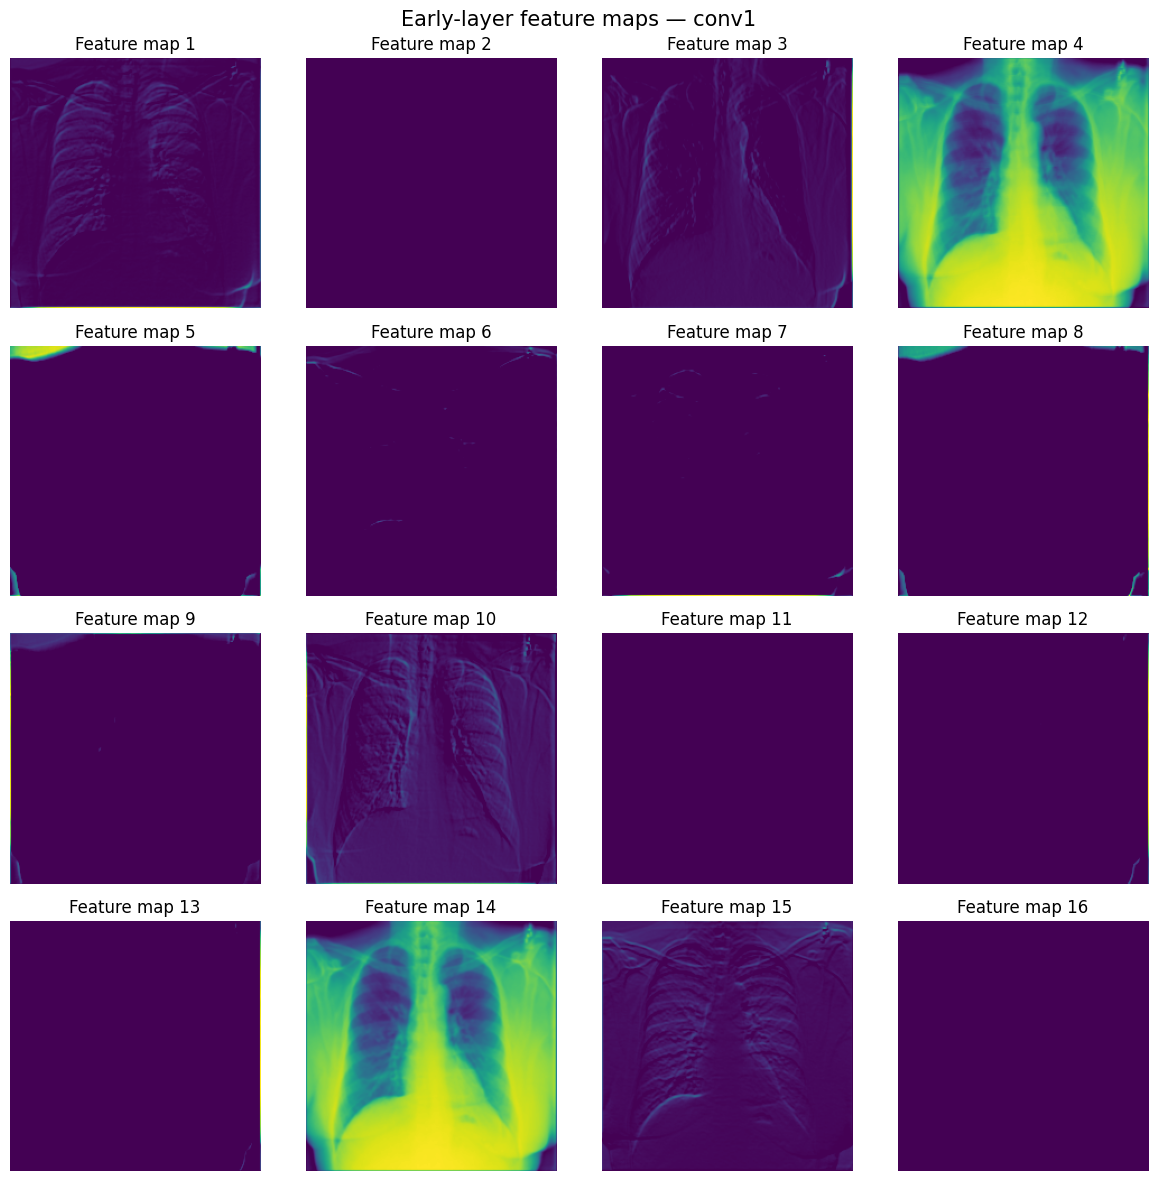

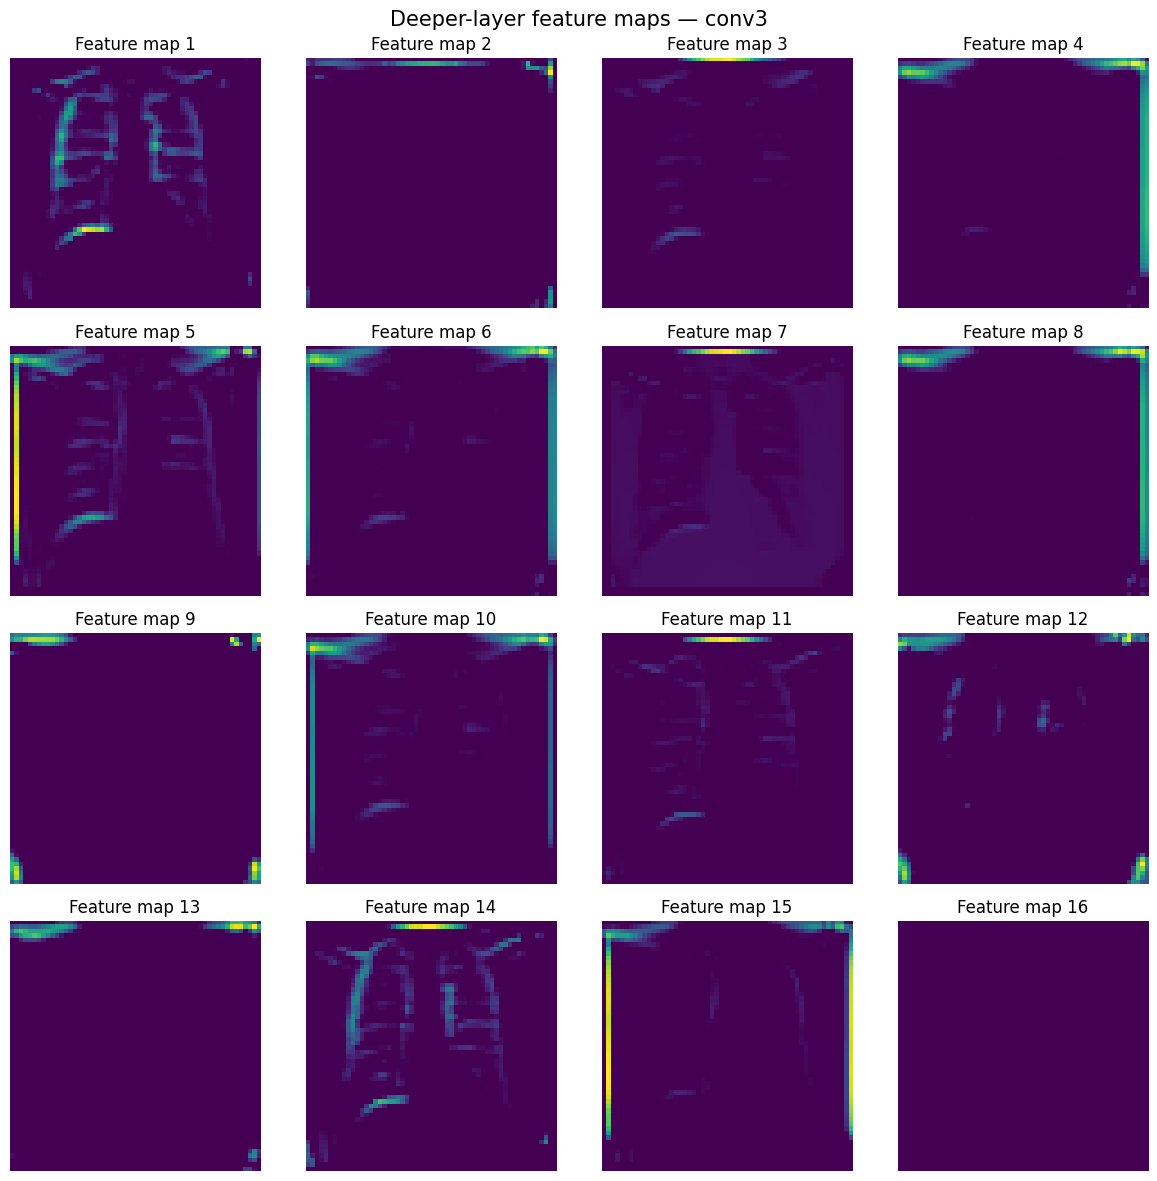

In [17]:
def plot_feature_maps(feature_maps, title, max_maps=16):
    n_maps = min(max_maps, feature_maps.shape[-1])
    cols = 4
    rows = int(np.ceil(n_maps / cols))

    fig, axes = plt.subplots(rows, cols, figsize=(12, 3 * rows))
    axes = np.array(axes).reshape(-1)

    for index in range(n_maps):
        axes[index].imshow(feature_maps[:, :, index], cmap="viridis")
        axes[index].set_title(f"Feature map {index + 1}")
        axes[index].axis("off")

    for index in range(n_maps, len(axes)):
        axes[index].axis("off")

    fig.suptitle(title, fontsize=15)
    plt.tight_layout()
    plt.show()


plot_feature_maps(early_maps, "Early-layer feature maps — conv1", max_maps=16)
plot_feature_maps(deep_maps, "Deeper-layer feature maps — conv3", max_maps=16)

## 14. Implement Grad-CAM

Grad-CAM computes the gradient of a selected class score with respect to the feature maps of the final convolutional layer. It averages those gradients to obtain channel weights, combines the feature maps, applies ReLU, and normalizes the resulting heatmap.

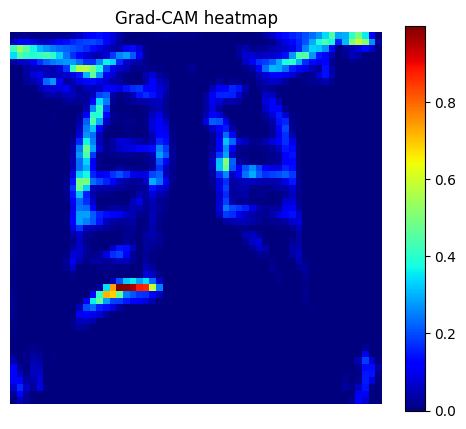

In [18]:
def make_gradcam_heatmap(image_batch, trained_model, last_conv_layer_name, class_index=None):
    """Create a Grad-CAM heatmap for one image batch of size 1."""

    grad_model = keras.Model(
        inputs=trained_model.inputs,
        outputs=[
            trained_model.get_layer(last_conv_layer_name).output,
            trained_model.output
        ]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(image_batch, training=False)

        if class_index is None:
            class_index = tf.argmax(predictions[0])

        class_score = predictions[:, class_index]

    gradients = tape.gradient(class_score, conv_outputs)

    if gradients is None:
        raise RuntimeError(
            "Gradients are None. Check that the selected layer is connected to the model output."
        )

    # Global-average-pool the gradients over height and width.
    channel_weights = tf.reduce_mean(gradients, axis=(0, 1, 2))

    # Weighted sum of the convolutional feature maps.
    conv_output = conv_outputs[0]
    heatmap = tf.reduce_sum(conv_output * channel_weights, axis=-1)

    # Keep positive contributions and normalize to [0, 1].
    heatmap = tf.maximum(heatmap, 0)
    max_value = tf.reduce_max(heatmap)
    heatmap = tf.where(
        max_value > 0,
        heatmap / (max_value + keras.backend.epsilon()),
        tf.zeros_like(heatmap)
    )

    return heatmap.numpy(), predictions.numpy()


heatmap, gradcam_predictions = make_gradcam_heatmap(
    sample_batch,
    model,
    last_conv_layer_name="conv3"
)

plt.figure(figsize=(6, 5))
plt.imshow(heatmap, cmap="jet")
plt.title("Grad-CAM heatmap")
plt.colorbar()
plt.axis("off")
plt.show()

## 15. Overlay Grad-CAM on the original X-ray image

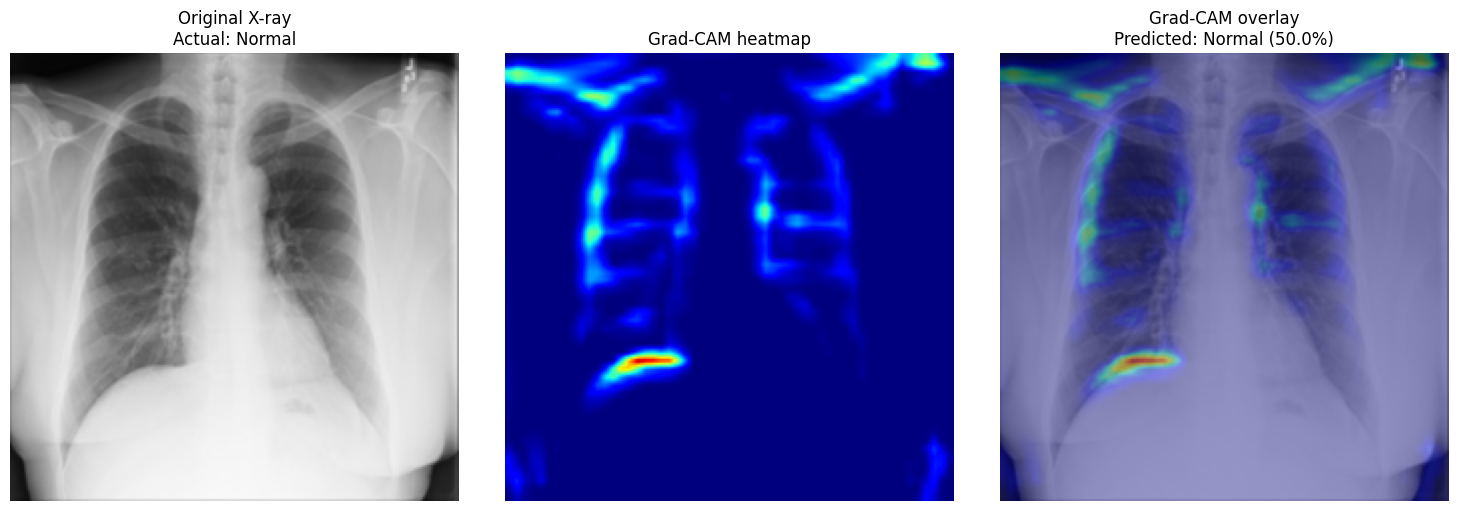

In [19]:
# Resize the heatmap to the input image dimensions.
heatmap_resized = tf.image.resize(
    heatmap[..., np.newaxis],
    IMG_SIZE,
    method="bilinear"
).numpy().squeeze()

# Prepare original image for display.
original_image = np.clip(sample_image.numpy() / 255.0, 0.0, 1.0)

# Convert heatmap values to an RGB color map.
heatmap_rgb = plt.get_cmap("jet")(heatmap_resized)[..., :3]

# Blend heatmap with original image.
ALPHA = 0.40
overlay = np.clip(
    (1.0 - ALPHA) * original_image + ALPHA * heatmap_rgb,
    0.0,
    1.0
)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original_image)
plt.title(f"Original X-ray\nActual: {CLASS_NAMES[actual_label]}")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap_resized, cmap="jet", vmin=0, vmax=1)
plt.title("Grad-CAM heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(overlay)
plt.title(
    f"Grad-CAM overlay\nPredicted: {CLASS_NAMES[predicted_class]} "
    f"({confidence * 100:.1f}%)"
)
plt.axis("off")

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "gradcam_overlay.png"), dpi=180)
plt.show()

## 16. Generate Grad-CAM for several test images (optional)

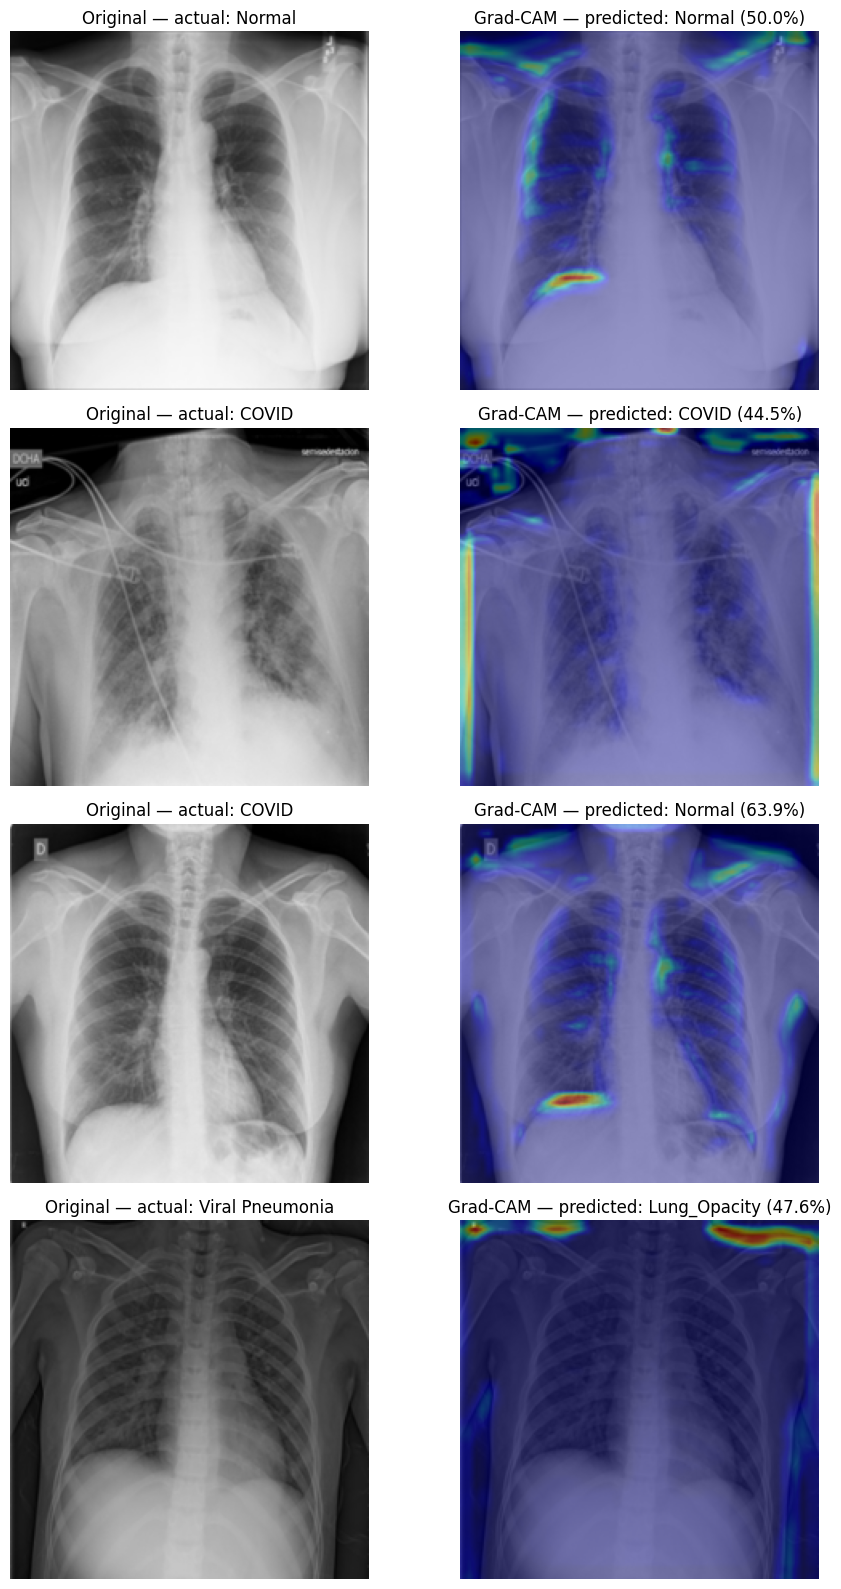

In [20]:
NUM_EXAMPLES = 4

fig, axes = plt.subplots(NUM_EXAMPLES, 2, figsize=(10, 4 * NUM_EXAMPLES))

for i in range(NUM_EXAMPLES):
    image_path = X_test[i]
    true_label = int(y_test[i])

    image_tensor, _ = load_image(
        tf.constant(image_path),
        tf.constant(true_label, dtype=tf.int32)
    )
    image_batch = tf.expand_dims(image_tensor, axis=0)

    image_heatmap, image_predictions = make_gradcam_heatmap(
        image_batch,
        model,
        last_conv_layer_name="conv3"
    )

    pred_class = int(np.argmax(image_predictions[0]))
    pred_confidence = float(image_predictions[0][pred_class])

    resized_map = tf.image.resize(
        image_heatmap[..., np.newaxis],
        IMG_SIZE,
        method="bilinear"
    ).numpy().squeeze()

    original = np.clip(image_tensor.numpy() / 255.0, 0.0, 1.0)
    colored_map = plt.get_cmap("jet")(resized_map)[..., :3]
    combined = np.clip(0.6 * original + 0.4 * colored_map, 0.0, 1.0)

    axes[i, 0].imshow(original)
    axes[i, 0].set_title(f"Original — actual: {CLASS_NAMES[true_label]}")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(combined)
    axes[i, 1].set_title(
        f"Grad-CAM — predicted: {CLASS_NAMES[pred_class]} "
        f"({pred_confidence * 100:.1f}%)"
    )
    axes[i, 1].axis("off")

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "multiple_gradcam_examples.png"), dpi=180)
plt.show()

## 17. Save the model and XAI outputs to Google Drive

In [21]:
final_model_path = os.path.join(OUTPUT_DIR, "covid_radiography_cnn_xai.keras")
model.save(final_model_path)

print("Model saved:", final_model_path)
print("Results folder:", OUTPUT_DIR)
print("Saved visualizations include:")
for filename in [
    "training_curves.png",
    "confusion_matrix.png",
    "gradcam_overlay.png",
    "multiple_gradcam_examples.png"
]:
    file_path = os.path.join(OUTPUT_DIR, filename)
    print(f"  {filename}: {'present' if os.path.exists(file_path) else 'not generated yet'}")

Model saved: /content/drive/MyDrive/XAI_CNN_Results/covid_radiography_cnn_xai.keras
Results folder: /content/drive/MyDrive/XAI_CNN_Results
Saved visualizations include:
  training_curves.png: present
  confusion_matrix.png: present
  gradcam_overlay.png: present
  multiple_gradcam_examples.png: present


## 18. Conclusion for the practical

A CNN was trained to classify chest X-ray images into four categories. Feature maps from an early and a deeper convolutional layer were visualized to inspect the representations learned at different depths. Grad-CAM was then applied to the final convolutional layer to produce a class-specific heatmap and overlay it on the input X-ray. These visualizations provide insight into which image patterns influence the model's prediction and demonstrate how XAI can improve the interpretability of CNNs.

**Dataset citation:** T. Rahman et al., “Can AI help in screening Viral and COVID-19 pneumonia?,” *Computers in Biology and Medicine*, 2020. Refer to the [Kaggle dataset page](https://www.kaggle.com/datasets/tawsifurrahman/covid19-radiography-database) for the dataset creators' citation details and current terms of use.

**Interpretation caution:** A Grad-CAM heatmap is a model-explanation visualization, not a clinical diagnosis or proof that the highlighted tissue caused a disease.